# Laboratório: filas, escalonamento e USL

**Pergunta:** como executar um lote de tarefas independentes em workers com capacidades diferentes? E por que aumentar o paralelismo nem sempre ajuda?

O notebook usa **simulações declaradamente didáticas** para explorar políticas de escalonamento e a USL. Um script complementar (`benchmark_filas_cpu.py`) permite **medir execução real**. Não confunda curvas simuladas com resultados experimentais.


In [ ]:
from dataclasses import dataclass
import heapq
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

@dataclass
class Execucao:
    tarefa: int
    worker: int
    inicio: float
    fim: float


def escalonar(trabalhos, velocidades, politica="fila"):
    p = len(velocidades)
    assert p > 0 and all(v > 0 for v in velocidades)
    registros = []
    if politica == "estatica":
        livres = [0.0] * p
        for i, trabalho in enumerate(trabalhos):
            worker = i % p
            inicio = livres[worker]
            fim = inicio + trabalho / velocidades[worker]
            livres[worker] = fim
            registros.append(Execucao(i, worker, inicio, fim))
    elif politica == "fila":
        disponiveis = [(0.0, w) for w in range(p)]
        heapq.heapify(disponiveis)
        for i, trabalho in enumerate(trabalhos):
            inicio, worker = heapq.heappop(disponiveis)
            fim = inicio + trabalho / velocidades[worker]
            registros.append(Execucao(i, worker, inicio, fim))
            heapq.heappush(disponiveis, (fim, worker))
    else:
        raise ValueError("Use 'estatica' ou 'fila'")
    return registros


def metricas(registros, p):
    T = max((r.fim for r in registros), default=0.0)
    ocupado = np.zeros(p)
    tarefas_por_worker = np.zeros(p, dtype=int)
    for r in registros:
        ocupado[r.worker] += r.fim - r.inicio
        tarefas_por_worker[r.worker] += 1
    return {"makespan": T, "vazao": len(registros)/T if T else float("nan"),
            "ocupacao": ocupado/T if T else np.zeros(p),
            "tarefas_por_worker": tarefas_por_worker}


def gantt(registros, titulo):
    p = max(r.worker for r in registros)+1
    fig, ax = plt.subplots(figsize=(10, max(2, .65*p+1)))
    for r in registros:
        ax.broken_barh([(r.inicio, r.fim-r.inicio)], (r.worker-.33, .66),
                       facecolors=f"C{r.worker%10}", edgecolors="white")
        if len(registros) <= 24:
            ax.text((r.inicio+r.fim)/2, r.worker, str(r.tarefa+1),
                    ha="center", va="center", fontsize=8)
    ax.set_yticks(range(p), [f"Worker {i+1}" for i in range(p)])
    ax.set_xlabel("Tempo (unidades)")
    ax.set_xlim(left=0)
    ax.set_title(titulo)
    ax.grid(axis="x", alpha=.2)
    plt.show()

print("Simulador carregado.")

Simulador carregado.


## Experimento 1 — Divisão estática × fila dinâmica

**Hipóteses:** 12 tarefas iguais, todas disponíveis em $t=0$. Worker A processa uma tarefa em **2 min** e B em **4 min**. Sem custo de despacho. A política **estática** distribui tarefas alternadamente; a política **fila** atribui a próxima tarefa ao primeiro worker livre.

**Previsão dos alunos:** quanto tempo cada política levará para concluir o lote (*makespan*)?

estatica | makespan=24.0 min | vazão=0.500 tarefa/min | tarefas/worker=[np.int64(6), np.int64(6)]


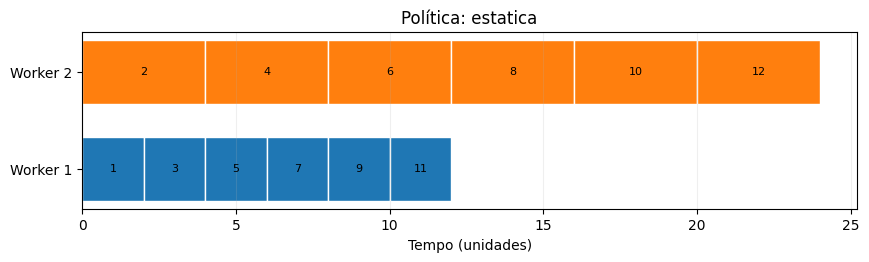

fila     | makespan=16.0 min | vazão=0.750 tarefa/min | tarefas/worker=[np.int64(8), np.int64(4)]


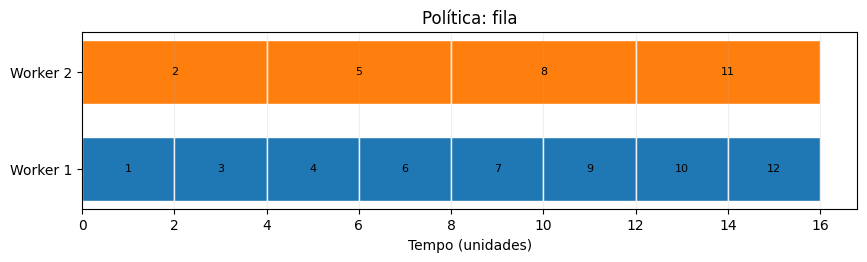

In [ ]:
trabalhos = [2.0] * 12
velocidades = [1.0, .5]
for politica in ("estatica", "fila"):
    rs = escalonar(trabalhos, velocidades, politica)
    r = metricas(rs, 2)
    print(f"{politica:8s} | makespan={r['makespan']:.1f} min | "
          f"vazão={r['vazao']:.3f} tarefa/min | "
          f"tarefas/worker={list(r['tarefas_por_worker'])}")
    gantt(rs, f"Política: {politica}")

**Discussão:** a distribuição estática (6+6 tarefas) termina em 24 min; a dinâmica (8+4) em 16 min. A fila dinâmica se ajusta à heterogeneidade **sem conhecer antecipadamente as velocidades**. Isso não demonstra otimalidade universal.

## Experimento 2 — Tarefas com durações variadas

Com 80 tarefas de trabalho aleatório e quatro workers heterogêneos, compare o *makespan*, a ocupação e a contagem de tarefas por worker. As tarefas são independentes e não preemptivas.

estatica | makespan=55.37 | vazão=1.445 | tarefas/worker=[np.int64(20), np.int64(20), np.int64(20), np.int64(20)] | ocupação=[np.float64(0.46), np.float64(1.0), np.float64(0.34), np.float64(0.64)]


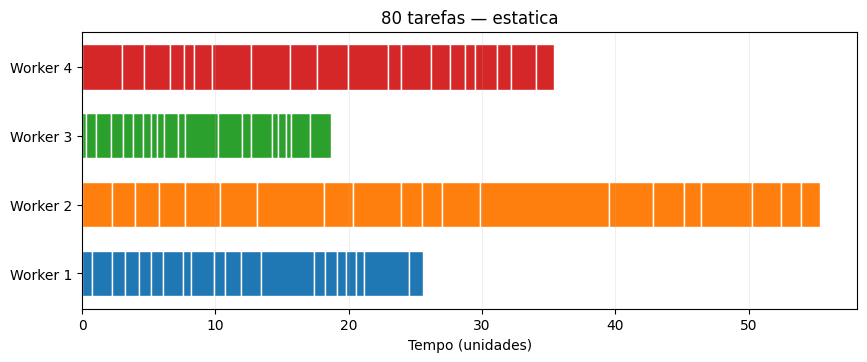

fila     | makespan=30.00 | vazão=2.667 | tarefas/worker=[np.int64(21), np.int64(11), np.int64(31), np.int64(17)] | ocupação=[np.float64(0.96), np.float64(0.97), np.float64(0.99), np.float64(1.0)]


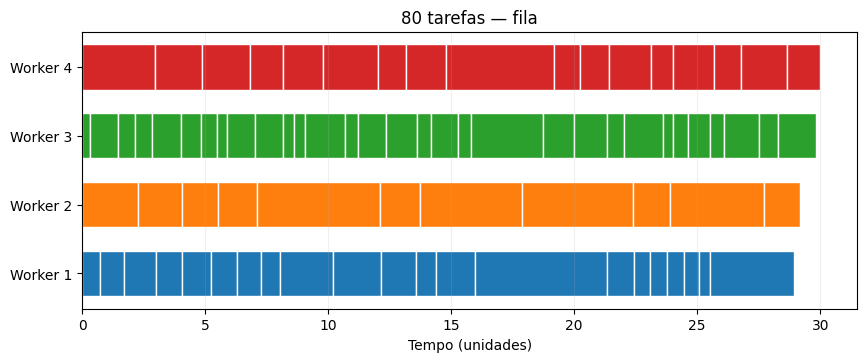

Redução do makespan (%): 45.8


In [ ]:
rng = np.random.default_rng(2026)
trabalhos = rng.lognormal(mean=.1, sigma=.5, size=80)
velocidades = [1.0, .55, 1.35, .75]
resultados = {}
for politica in ("estatica", "fila"):
    rs = escalonar(trabalhos, velocidades, politica)
    resultados[politica] = metricas(rs, len(velocidades))
    r = resultados[politica]
    print(f"{politica:8s} | makespan={r['makespan']:.2f} | vazão={r['vazao']:.3f} | "
          f"tarefas/worker={list(r['tarefas_por_worker'])} | "
          f"ocupação={list(np.round(r['ocupacao'],2))}")
    gantt(rs, f"80 tarefas — {politica}")
print("Redução do makespan (%):", round(100*(1-resultados['fila']['makespan']/resultados['estatica']['makespan']),1))

**Conceitos:**

- **Makespan:** $T_{\max}=\max_i C_i$, quando a última tarefa termina.
- **Vazão do lote:** $N/T_{\max}$.
- **Ocupação do worker:** tempo ocupado dividido pelo makespan.
- Uma fila dinâmica não é necessariamente ótima quando o custo das tarefas varia muito ou há custo de despacho.
- A **Lei de Little** $L=\lambda W$ se aplica a médias de sistemas em regime estável sob condições apropriadas, e **não automaticamente** ao lote finito deste exemplo.

## Experimento 3 — USL: contenção e coerência

A capacidade normalizada da Universal Scalability Law é:

$$
C(p)=\frac{p}{1+\alpha(p-1)+\beta p(p-1)}
$$

$p$ indica concorrência; $\alpha$ e $\beta$ capturam penalidades **efetivas** de contenção e coerência. Os parâmetros abaixo são **escolhidos artificialmente**, não medidos. Seu ajuste não identifica sozinho o gargalo físico.

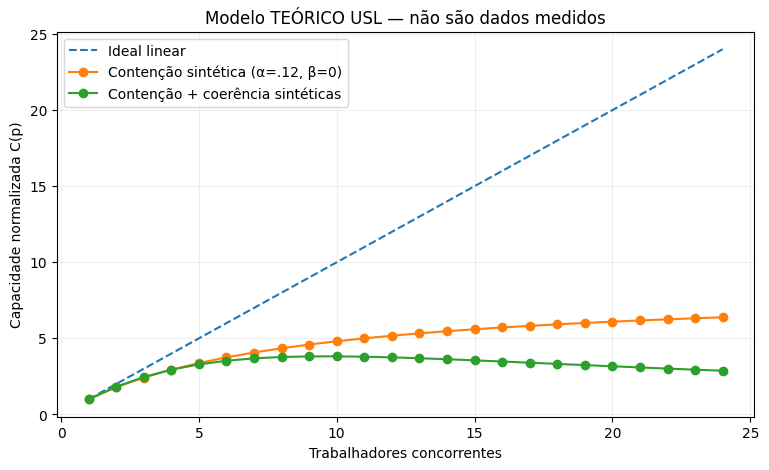

Ótimo contínuo previsto: p*=9.59 | ótimo inteiro de 1 a 24: 10


In [ ]:
def usl(p, alpha=0.08, beta=0.01):
    p = np.asarray(p, dtype=float)
    return p/(1+alpha*(p-1)+beta*p*(p-1))

p = np.arange(1,25)
fig,ax = plt.subplots(figsize=(9,5))
ax.plot(p,p,"--",label="Ideal linear")
ax.plot(p,usl(p,.12,0),"o-",label="Contenção sintética (α=.12, β=0)")
ax.plot(p,usl(p,.08,.01),"o-",label="Contenção + coerência sintéticas")
ax.set(xlabel="Trabalhadores concorrentes",ylabel="Capacidade normalizada C(p)",
       title="Modelo TEÓRICO USL — não são dados medidos")
ax.legend();ax.grid(alpha=.2);plt.show()
alpha,beta=.08,.01
p_est = ((1-alpha)/beta)**.5
print(f"Ótimo contínuo previsto: p*={p_est:.2f} | ótimo inteiro de 1 a 24: {p[np.argmax(usl(p,alpha,beta))]}")

**Perguntas:**

1. Com $\beta=0$, a capacidade cai ou apenas satura quando $p\to\infty$?
2. Por que $\beta>0$ pode levar à **retroescala** (mais workers, menor capacidade)?
3. Quais gargalos reais poderiam provocar contenção? Locks, memória, disco, banda de rede, filas internas etc.

### Uma simulação com interferência imposta

Vamos **impor** a cada worker um fator de desaceleração $D(p)=1+\alpha(p-1)+\beta p(p-1)$. Isso gera, por construção, capacidade agregada aproximadamente $p/D(p)$, com pequenos desvios por esvaziamento do lote. Não é evidência de que um sistema real obedeça à USL.

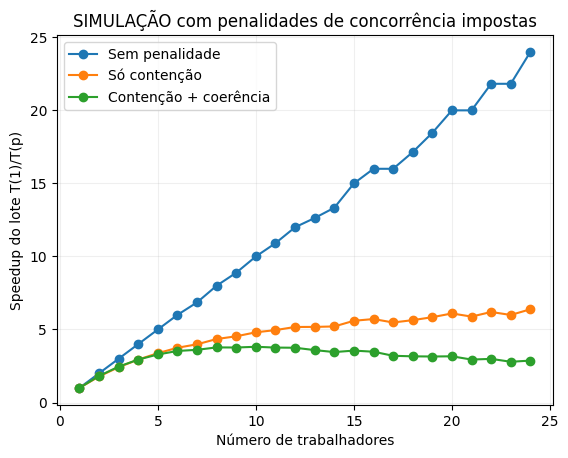

In [ ]:
tarefas=[1.0]*240
ps=np.arange(1,25)
for a,b,nome in [(0,0,"Sem penalidade"),(.12,0,"Só contenção"),(.08,.01,"Contenção + coerência")]:
    tempos=[]
    for n in ps:
        slowdown=1+a*(n-1)+b*n*(n-1)
        registros=escalonar(tarefas, [1.0/slowdown]*int(n), "fila")
        tempos.append(metricas(registros,int(n))["makespan"])
    speedup=tempos[0]/np.array(tempos)
    plt.plot(ps,speedup,"o-",label=nome)
plt.xlabel("Número de trabalhadores")
plt.ylabel("Speedup do lote T(1)/T(p)")
plt.title("SIMULAÇÃO com penalidades de concorrência impostas")
plt.legend();plt.grid(alpha=.2);plt.show()

## Experimento 4 — Medição real (opcional)

Abra um terminal na pasta com `benchmark_filas_cpu.py` e execute:

```bash
python benchmark_filas_cpu.py --tasks 120 --rounds 50000 --workers 1,2,4,6,8 --repeats 3
```

O programa utiliza **ProcessPoolExecutor** e uma carga CPU-bound para medir tempos reais, escrevendo `medicoes_filas_usl.csv`. Se as execuções forem muito rápidas, aumente `--rounds`.

O speedup do lote $S(p)=T(1)/T(p)$ é uma medida útil, mas não equivale exatamente à capacidade em regime estacionário: criação de processos, início e esvaziamento do lote também influenciam. **A queda de desempenho não é garantida**; depende da máquina e de seus limites.

In [ ]:
caminho = Path("medicoes_filas_usl.csv")
if not caminho.exists():
    print("Execute o benchmark externo para produzir medições reais:", caminho)
else:
    with caminho.open(encoding="utf-8") as f:
        dados=list(csv.DictReader(f))
    ps=sorted({int(x["workers"]) for x in dados})
    medianas={p:float(np.median([float(x["seconds"]) for x in dados
                  if int(x["workers"])==p])) for p in ps}
    s=np.array([medianas[1]/medianas[p] for p in ps])
    plt.plot(ps,ps,"--",label="Ideal")
    plt.plot(ps,s,"o-",label="Speedup MEDIDO")
    plt.xlabel("Processos simultâneos");plt.ylabel("Speedup T(1)/T(p)")
    plt.title("Benchmark real: medianas de execuções")
    plt.legend();plt.grid(alpha=.2);plt.show()
    for p,sp in zip(ps,s):
        print(f"p={p:2d} | mediana={medianas[p]:6.3f} s | speedup={sp:.2f} | eficiência={sp/p:.1%}")
    print("Ajustar USL a dados reais exige verificar a adequação do modelo e a qualidade das medições.")

Execute o benchmark externo para produzir medições reais: medicoes_filas_usl.csv


## Onde entra Kubernetes?

| Conceito teórico | Tradução possível para Kubernetes |
|---|---|
| Worker | Processo executado em um Pod |
| Máquina | Node |
| Fila central | Redis, RabbitMQ, banco ou fila própria da aplicação |
| Retirada dinâmica de tarefas | Workers consultam a fila quando disponíveis |
| Concorrência | Número de réplicas de workers e recursos disponíveis |
| Escolha do host do worker | `kube-scheduler` posiciona Pods em Nodes |

O **Kubernetes não substitui automaticamente o escalonador de itens de trabalho**. Seu scheduler padrão decide onde **Pods** serão executados; a fila e a política de despacho das tarefas continuam sendo decisões arquiteturais da aplicação. Há padrões oficiais de *Job* com *work queue*: https://kubernetes.io/docs/tasks/job/fine-parallel-processing-work-queue/

**Leituras:** Gunther, *Guerrilla Capacity Planning*; Little, *A Proof for the Queuing Formula: L=λW*; documentação de Kubernetes Jobs e *work queues*.